## 01-EDA Exploratory Data Analysis for Pitt dataset

In this notebook, we are going to do EDA (Exploratory Data Analysis) on the train set, with text data

In [1]:
# import required packages
import pandas as pd
import os
from wordcloud import WordCloud, STOPWORDS, ImageColorGenerator
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [2]:
# labels
# AD = Alzheimer's Disease (positive class)
# CN = Cognitively Normal (negative class)

In [3]:
# please point to correct downloaded transcribed folders of the original dataset
data_path = "../../../data/" 

fname = data_path + "pitt/pitt_train_txt.csv"
train_df = pd.read_csv(fname)
print("Length =", len(train_df))
train_df.head()

Length = 398


,file_id,text,target,id,split_name
0,001-0,mhm .\nalright .\nthere's &-um a young boy tha...,AD,1,train
1,001-2,mhm .\nthere's a young boy &-uh going in a coo...,AD,1,train
2,003-0,here's a cookie jar .\nand the lid is off the ...,AD,3,train
3,005-0,the boy is slipping off the stool .\nhe's tryi...,AD,5,train
4,005-2,okay ‡ he's fallin(g) off a chair .\nshe's &-...,AD,5,train


In [4]:
# build word-clouds
def make_wordcloud(text_list):
    """
    display a wordcloud based on the text list
    parameters:
        text_list: list of text (paragraphs)
    returns:
        list of frequent words        
    """
    text = "\n".join(text_list).lower()
    wordcloud = WordCloud().generate(text)

    # process text and return counts of frequent words
    result = sorted(WordCloud().process_text(text).items(), 
                    key=lambda item: item[1],
                    reverse=True
                   )
    
    
    plt.imshow(wordcloud)
    plt.axis("off")
    plt.show()

    return result

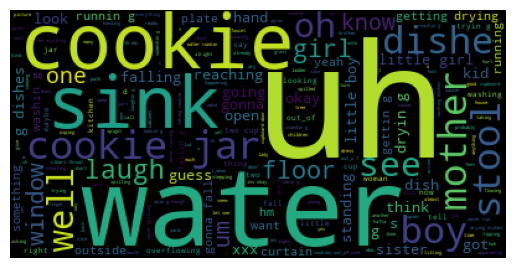

[('uh', 534), ('water', 201), ('cookie', 195), ('sink', 179), ('cookie jar', 162), ('mother', 155), ('stool', 154), ('dishe', 149), ('boy', 145), ('well', 135), ('see', 123), ('oh', 121), ('laugh', 105), ('girl', 96), ('floor', 96), ('window', 90), ('one', 83), ('um', 79), ('know', 77), ('little girl', 77), ('look', 74), ('little boy', 71), ('xxx', 66), ('g', 65), ('going', 60), ('got', 57), ('reaching', 55), ('kid', 54), ('okay', 53), ('think', 52), ('guess', 51), ('sister', 51), ('hand', 50), ('standing', 49), ('gonna', 49), ('falling', 48), ('dryin g', 48), ('g dishes', 47), ('open', 45), ('s', 43), ('dish', 43), ('runnin g', 43), ('getting', 42), ('want', 41), ('something', 39), ('drying', 39), ('yeah', 39), ('curtain', 39), ('running', 37), ('plate', 37)]


In [5]:
# see the most frequent words of AD (positive) group
ad_top_words = make_wordcloud(train_df.query("target == 'AD'")["text"].tolist())
print(ad_top_words[:50])
ad_top_words_set = set([w
                        for w, count in ad_top_words[:200]
                       ])
ad_top_words_dict = {w:count
                     for w, count in ad_top_words
                    }

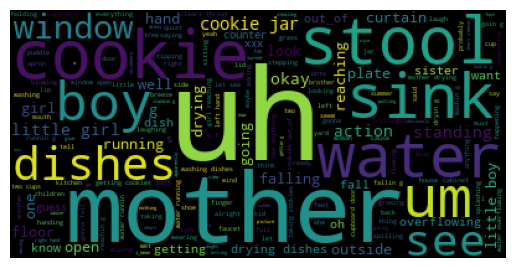

[('uh', 399), ('mother', 199), ('cookie', 182), ('stool', 174), ('water', 173), ('sink', 171), ('um', 143), ('boy', 127), ('dishes', 124), ('see', 117), ('window', 111), ('cookie jar', 109), ('okay', 90), ('little girl', 87), ('action', 84), ('standing', 82), ('reaching', 74), ('floor', 73), ('hand', 67), ('look', 66), ('one', 63), ('running', 61), ('falling', 61), ('curtain', 60), ('girl', 59), ('open', 58), ('well', 57), ('little boy', 57), ('g', 53), ('outside', 53), ('going', 52), ('drying', 50), ('plate', 49), ('overflowing', 47), ('oh', 45), ('getting', 45), ('sister', 44), ('fall', 43), ('drying dishes', 43), ('know', 42), ('out_of', 40), ('want', 37), ('dish', 37), ('s', 33), ('guess', 33), ('xxx', 32), ('counter', 32), ('washing dishes', 32), ('kitchen', 31), ('two cups', 31)]


In [6]:
# see the most frequent words of CN (negative) group
cn_top_words = make_wordcloud(train_df.query("target == 'CN'")["text"].tolist())
print(cn_top_words[:50])
cn_top_words_set = set([w
                        for w, count in cn_top_words[:200]
                       ])
cn_top_words_dict = {w:count
                     for w, count in cn_top_words
                    }

In [7]:
# check counts of some different words
print(ad_top_words_dict["mother"])
print(cn_top_words_dict["mother"])


155
199


In [8]:
# observe the difference in 2 word set
ad_unique = ad_top_words_set - cn_top_words_set
cn_unique = cn_top_words_set - ad_top_words_set
print("AD unique words =\n", ad_unique)
print("----------------")
print("CN unique words =\n", cn_unique)


AD unique words =
 {'time', 'somethin g', 'c', 'yet', 'g dishes', 'inv okay', 'still', 'make', 'part', 'chair', 'huh', 'water run', 'yes', 'spigot', 'doin g', 'young', 'u', 'call', 'many', 'hurt', 'way', 'spilled', 'water spilling', 'mom', 'coming', 'sh', 'th em', 'two cup', 'takin g', 'mama', 'upset', 'taking cookie', 'much', 't', 'already', 'though', 'come', 'take', 'hafta', 'w', 'dishe', 'th', 'good', 'out_o f', 'laughin g', 'tryin g', 'even', 'kind', 'big', 'dry', 'turn'}
----------------
CN unique words =
 {'moving', 'splashing', 'shrubbery', 'wearing', 'three', 'far', 'turned', 'laughing', 'mother drying', 'nothing', 'run', 'coming out_of', 'summer', 'day', 'taking cookies', 'child', 'window open', 'arm', 'left', 'two cups', 'dishes', 'o f', 'holding', 'growing', 'sitting', 'sort', 'short sleeve', 'girl reaching', 'towel', 'left hand', 'high', 'water overflowing', 'mean', 'getting cookies', 'saying', 'giving', 'putting', 'puddle', 'obviously', 'lip', 'right hand', 'view', 'side',

In [9]:
ad_count = len(train_df.query("target == 'AD'"))
cn_count = len(train_df.query("target == 'CN'"))

print(f"Number of AD examples = {ad_count}, ratio = {ad_count * 100 / len(train_df) :.0f} %")
print(f"Number of CN examples = {cn_count}, ratio = {cn_count * 100 / len(train_df) :.0f} %")

Number of AD examples = 218, ratio = 55 %
Number of CN examples = 180, ratio = 45 %


We can see we have total of 337 examples, with 187 positive (AD) and 150 negative (CN). The train_set is relatively balanced (55% - 45%). 